## Phase 1: Setup and Data Ingestion
Load required libraries, ingest raw data, drop duplicates, and standardize categorical labels.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier 
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, auc, mean_squared_error
from scipy.stats import randint, uniform 

RANDOM_STATE = 42



In [2]:
# Data Ingestion
raw_data = pd.read_csv(
    '/Users/USER/Desktop/datathon/spe_dseat_datathon/data/raw/oil_presence_trainset.csv',
    keep_default_na=False,
    na_values=['']
)

# Standardize Labels and Drop Duplicates
df = raw_data.drop_duplicates().copy()
df['Trap_Type'] = df['Trap_Type'].replace({'None': 'No_Structure'})
df.head()

,Rock_Type,Porosity,Permeability,Trap_Type,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Oil_Presence
0,Limestone,17.667992,834.277472,No_Structure,0.705933,2.431355,2228.0,1
1,Limestone,27.665758,578.158034,No_Structure,0.545806,2.606158,1610.0,0
2,Sandstone,28.855946,404.790685,No_Structure,0.167530,1.143136,2344.0,0
3,Sandstone,0.410957,887.836673,Dome,0.026852,2.673532,NaN,0
4,Shale,16.490538,562.288802,No_Structure,NaN,2.064440,NaN,0


## Phase 2: Exploratory Data Analysis & Missingness Audit

**Data Cleaning & Quality Report:**
* **Missing Values:** Porosity (26%), Permeability (40%), Seismic_Score (34%), Proximity_to_Oil_Field (32%), Estimated_Reservoir_Depth (43%).
* **Data Quality:** Numerical columns contain the missing rows. No format irregularities, wrong spellings, or hidden characters were observed.
* **Duplicates:** No unusual repetition in numerical columns. Duplicates discovered within columns with object data types were considered okay due to the nature of the dataset.

**Strategy:** Given the high importance of each row, dropping rows is not advisable. We will handle missing numerical values using MICE (Multiple Imputation by Chained Equations) to predict and fill them based on relationships with other features.


In [3]:
# separate columns by data type
num_cols = df.select_dtypes(include=[np.number]).columns
obj_cols = df.select_dtypes(include=['object']).columns

print("Duplicate Check:")
print("-" * 40)
# check for exact row duplicates across the entire df
total_duplicates = df.duplicated().sum()
print(f"Total exact row duplicates in dataset: {total_duplicates}")

# check for duplicates specifically within numerical columns
if len(num_cols) > 0:
    num_duplicates = df.duplicated(subset=num_cols).sum()
    print(f"Rows with identical numerical values across all numerical columns: {num_duplicates}")

# check for unique value counts in object columns
print("\nUnique value counts in Object Columns:")
for col in obj_cols:
    unique_count = df[col].nunique()
    total_count = len(df[col])
    print(f" - {col}: {unique_count} unique categories across {total_count} rows.")
    

Duplicate Check:
----------------------------------------
Total exact row duplicates in dataset: 0
Rows with identical numerical values across all numerical columns: 6

Unique value counts in Object Columns:
 - Rock_Type: 3 unique categories across 2994 rows.
 - Trap_Type: 4 unique categories across 2994 rows.


/var/folders/c8/7krwwn3d4fq45_lf7twc4d7w0000gn/T/ipykernel_7659/1656141245.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object']).columns


Missing Values Analysis
----------------------------------------


                   Column  Missing_Count  Missing_Percentage
Estimated_Reservoir_Depth           1268               42.27
             Permeability           1186               39.53
            Seismic_Score           1050               35.00
   Proximity_to_Oil_Field            943               31.43
                 Porosity            803               26.77




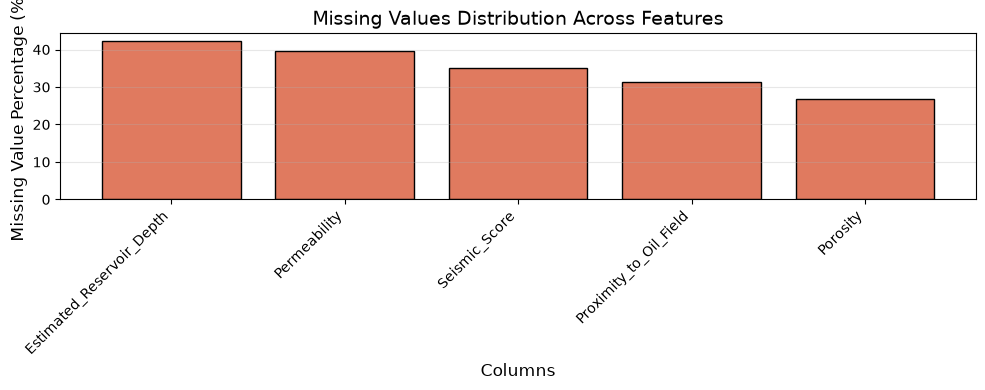

In [ ]:
# analyze missing values across all columns
print("Missing Values Analysis")
print("-"*40)

missing_data = pd.DataFrame({
    'Column': raw_data.columns,
    'Missing_Count': raw_data.isnull().sum(),
    'Missing_Percentage': (raw_data.isnull().sum() / len(raw_data) * 100).round(2)
})
missing_data = missing_data[missing_data['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

print("\n")
print(missing_data.to_string(index=False))
print("\n")

# Visualization: Bar chart of missing values
plt.figure(figsize=(10, 4))
plt.bar(missing_data['Column'], missing_data['Missing_Percentage'], edgecolor='black')
plt.xlabel('Columns', fontsize=12)
plt.ylabel('Missing Value Percentage (%)', fontsize=12)
plt.title('Missing Values Distribution Across Features', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:
# analyzing the numeric columns that actually need imputation
numeric_features = [
    'Porosity',
    'Permeability',
    'Seismic_Score',
    'Proximity_to_Oil_Field',
    'Estimated_Reservoir_Depth'
]

summary_table = pd.DataFrame({
    'Missing_Count': df[numeric_features].isna().sum(),
    'Missing_Percentage': (df[numeric_features].isna().sum() / len(df) * 100).round(2),
    'Mean': df[numeric_features].mean().round(3),
    'Median': df[numeric_features].median().round(3),
    'Std_Dev': df[numeric_features].std().round(3),
    'Skewness': df[numeric_features].skew().round(3)
}).sort_values('Missing_Count', ascending=False)

print('\nSummary statistics for the numeric features:')
print("-" * 50)
print(summary_table.to_string())
print('\n')


Summary statistics for the numeric features:
--------------------------------------------------
                           Missing_Count  Missing_Percentage      Mean    Median   Std_Dev  Skewness
Estimated_Reservoir_Depth           1262               42.15  2764.427  2772.500  1288.783    -0.027
Permeability                        1180               39.41   505.594   504.565   281.718    -0.015
Seismic_Score                       1044               34.87     0.491     0.486     0.287     0.046
Proximity_to_Oil_Field               937               31.30     2.546     2.551     1.471    -0.050
Porosity                             797               26.62    14.762    14.603     8.751     0.027




#### Brief summary of the statistics cell

In this dataset, mean and median are close for most numeric features and skewness is near 0, so the columns are not strongly skewed. That means simple methods (mean/median) are reasonable baselines for imputation, but we still need to compare methods objectively before choosing one.

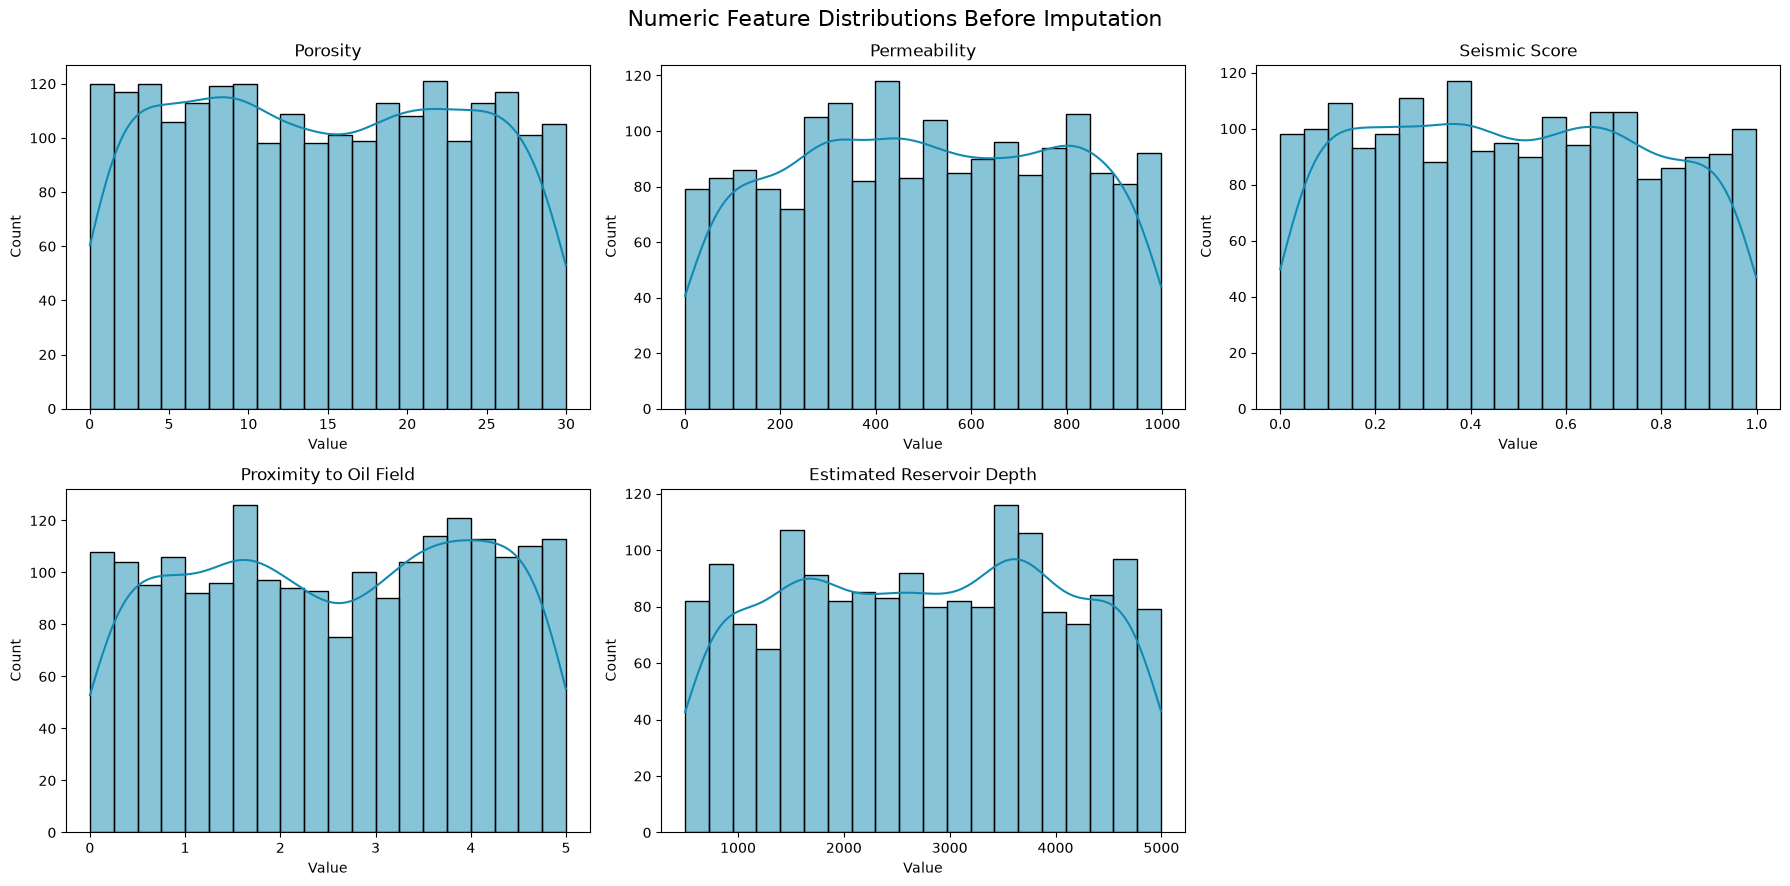

In [ ]:
# visualization of the distribution shape of each numeric column.
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle('Numeric Feature Distributions Before Imputation', fontsize=16)

for axis, feature in zip(axes.flatten(), numeric_features):
    sns.histplot(df[feature], bins=20, kde=True, ax=axis, color='#118ab2')
    axis.set_title(feature.replace('_', ' '))
    axis.set_xlabel('Value')
    axis.set_ylabel('Count')

axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show() 

#### Brief summary of the distribution plots

These histograms + KDE curves help us visually check distribution shape for each numeric feature before imputation. Here, the plots look mostly smooth and not heavily skewed, which supports using a model-based imputer that can preserve relationships between variables instead of injecting one repeated constant value (mean/median imputation method).

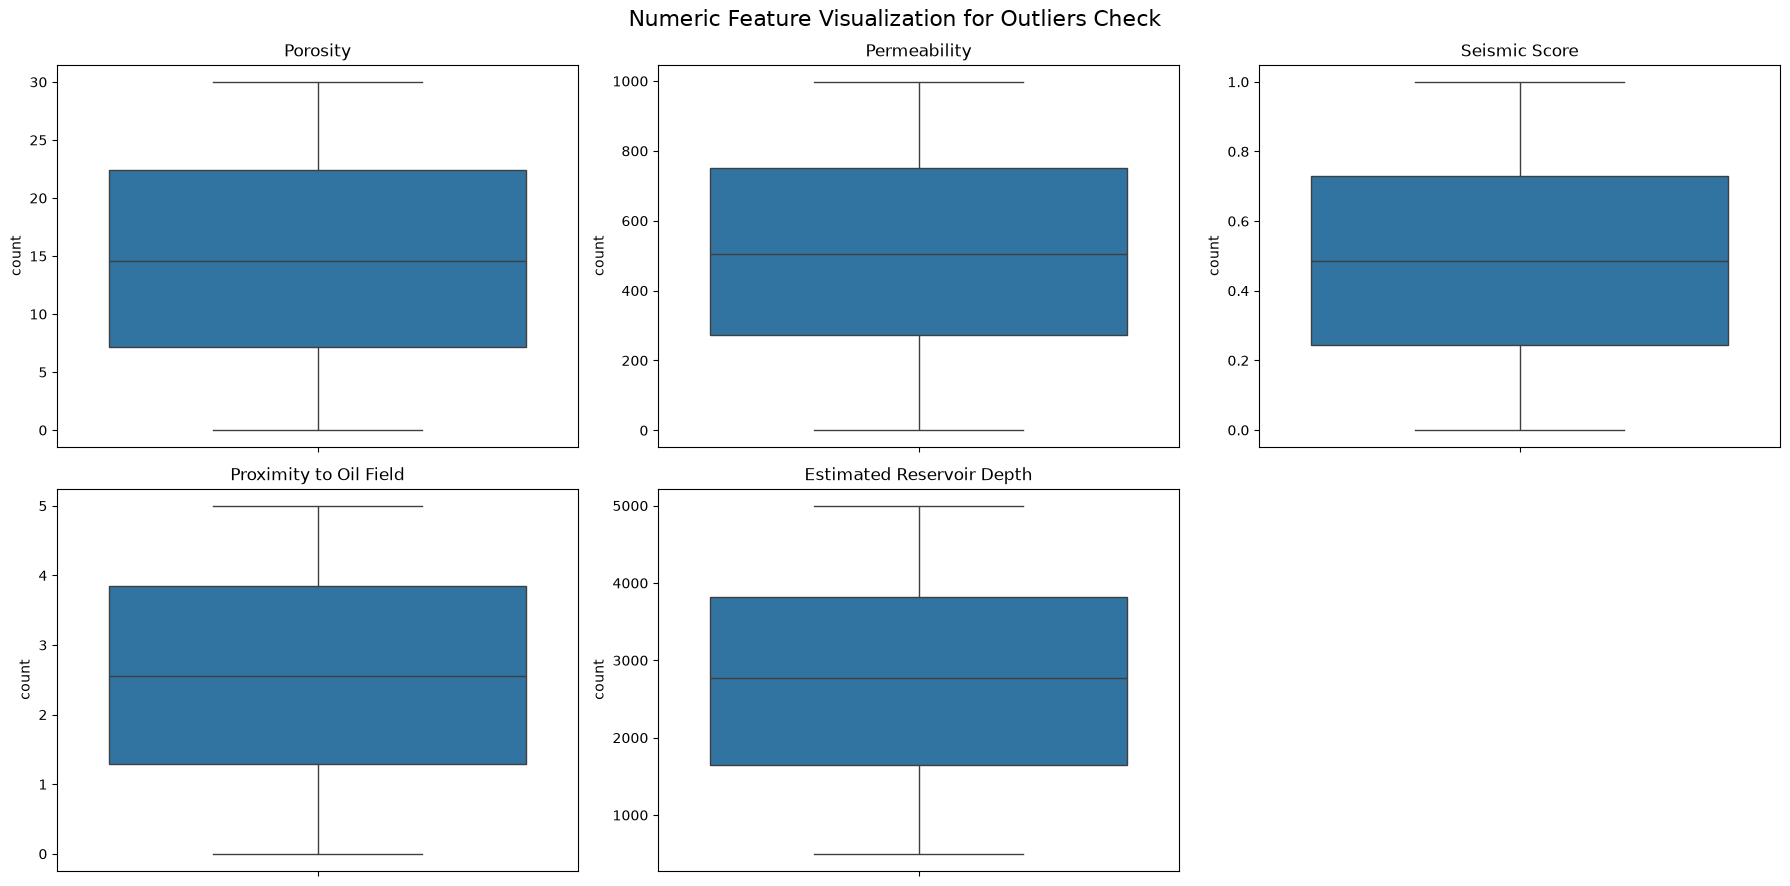

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle('Numeric Feature Visualization for Outliers Check', fontsize=16)

for axis, feature in zip(axes.flatten(), numeric_features):
    sns.boxplot(data = df,  y = feature, ax = axis)
    axis.set_title(feature.replace('_', ' '))
    axis.set_ylabel('count')

axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

#### Imputation Method Benchmarking
Compare the different imputation methods to understand the best method and why.

Imputation method comparison using masked observed values:
Method       RMSE
  MICE 519.450873
  Mean 519.497602
Median 519.863523
   KNN 601.882415


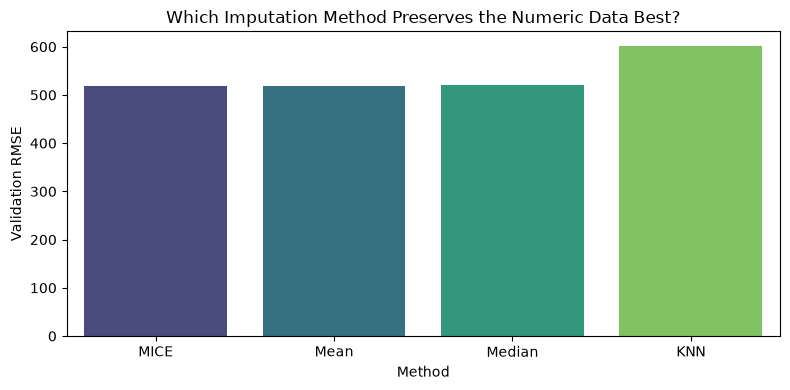

In [8]:
# compare the imputation methods by handling a small share of observed values as if they were missing, then measuring how well each method recovers those values using RMSE.
comparison_source = df[numeric_features].copy()
observed_positions = np.argwhere(comparison_source.notna().to_numpy())
rng = np.random.default_rng(42)
mask_size = max(1, int(len(observed_positions) * 0.1))
selected_positions = observed_positions[rng.choice(len(observed_positions), size=mask_size, replace=False)]
validation_mask = pd.DataFrame(False, index=comparison_source.index, columns=comparison_source.columns)
for row_idx, col_idx in selected_positions:
    validation_mask.iat[row_idx, col_idx] = True

masked_data = comparison_source.mask(validation_mask)
scaler = StandardScaler()
scaled_masked = pd.DataFrame(
    scaler.fit_transform(masked_data),
    columns=numeric_features,
    index=masked_data.index
)

imputer_trials = {
    'Mean': SimpleImputer(strategy='mean'),
    'Median': SimpleImputer(strategy='median'),
    'KNN': KNNImputer(n_neighbors=5, weights='distance'),
    'MICE': IterativeImputer(random_state=42, max_iter=20)
}

comparison_rows = []
validation_mask_array = validation_mask.to_numpy()
actual_values = comparison_source.to_numpy()[validation_mask_array]

for method_name, imputer in imputer_trials.items():
    imputed_scaled = pd.DataFrame(
        imputer.fit_transform(scaled_masked),
        columns=numeric_features,
        index=scaled_masked.index
    )
    imputed_values = pd.DataFrame(
        scaler.inverse_transform(imputed_scaled),
        columns=numeric_features,
        index=scaled_masked.index
    )

    predicted_values = imputed_values.to_numpy()[validation_mask_array]
    rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))

    comparison_rows.append({
        'Method': method_name,
        'RMSE': rmse
    })

comparison_results = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
print('Imputation method comparison using masked observed values:')
print(comparison_results.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_results, x='Method', y='RMSE', hue='Method', palette='viridis', legend=False)
plt.title('Which Imputation Method Preserves the Numeric Data Best?')
plt.xlabel('Method')
plt.ylabel('Validation RMSE')
plt.tight_layout()
plt.show()


#### Brief Summary (Imputation Method Comparison)

This cell compares imputation methods using a fair validation trick: hide some known values, impute them, then measure error (RMSE). Lower RMSE means better recovery of real values.

Result interpretation:
- **MICE** had the lowest RMSE (best preservation of data structure).
- **Mean/Median** were close, but they ignore multivariate relationships.
- **KNN** performed worst here, likely because high missingness weakens nearest-neighbor quality.

So we choose **MICE** for the numeric columns because it best preserves data integrity in this dataset.

## Phase 3: Feature Engineering & Leakage-Free MICE Imputation
To prevent data leakage, we **first split the data** into training and testing sets. 
We then use a `Pipeline` to apply One-Hot Encoding for categorical features, and MICE (`IterativeImputer`) alongside `StandardScaler` for numerical features. The imputer and scaler will only learn from the `X_train` distribution.


In [9]:
# Define Features and Target
X = df.drop(columns=['Oil_Presence'])
y = df['Oil_Presence']

# Split the data first to prevent data leakage during MICE imputation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print('\nClass distribution (train):')
print((y_train.value_counts(normalize=True) * 100).round(2).rename('Percent'))


X_train shape: (2395, 7)
X_test shape: (599, 7)

Class distribution (train):
Oil_Presence
0    72.19
1    27.81
Name: Percent, dtype: float64


In [10]:
# define numerical and categorical columns
numerical_cols = [
    'Porosity', 'Permeability', 'Seismic_Score', 
    'Proximity_to_Oil_Field', 'Estimated_Reservoir_Depth'
]
categorical_cols = ['Rock_Type', 'Trap_Type']

# create Pipeline for Numerical Features (StandardScaler -> MICE Imputer)
# using ExtraTreesRegressor to prevent outliers and improve imputation quality
num_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('imputer', IterativeImputer(
        estimator=ExtraTreesRegressor(n_estimators=10, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE, 
        max_iter=10
    ))
])

# create Pipeline for Categorical Features (One-Hot Encoding)
cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# combine into a ColumnTransformer Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numerical_cols),
        ('cat', cat_pipeline, categorical_cols)
    ],
    remainder='passthrough'
)

# fit the preprocessor only on training data to prevent leakage, then transform both
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# convert the processed arrays back to dataFrames for the modeling
feature_names = (
    numerical_cols + 
    preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_cols).tolist()
)

X_train_imputed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_imputed = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print("Preprocessing complete. No data leakage occurred.")
print('Remaining missing values in train set:', X_train_imputed.isna().sum().sum())
print('Remaining missing values in test set:', X_test_imputed.isna().sum().sum())


Preprocessing complete. No data leakage occurred.
Remaining missing values in train set: 0
Remaining missing values in test set: 0


/Users/USER/Desktop/datathon/spe_dseat_datathon/ml_venv/lib/python3.14/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [11]:
X_train_imputed.head()

,Porosity,Permeability,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Rock_Type_Sandstone,Rock_Type_Shale,Trap_Type_Dome,Trap_Type_Fault,Trap_Type_No_Structure
1449,0.502390,-0.026976,0.077204,-0.451775,0.671275,0.0,0.0,1.0,0.0,0.0
943,0.845216,-1.414507,1.610648,-0.080384,1.567189,0.0,1.0,0.0,0.0,1.0
826,0.027980,0.111731,-0.131827,-0.504821,-0.562735,0.0,0.0,0.0,0.0,0.0
2237,-1.395206,-1.295873,-0.645525,-0.612389,-0.893248,1.0,0.0,1.0,0.0,0.0
881,-0.692718,1.215248,-0.850408,-1.148393,1.419417,1.0,0.0,1.0,0.0,0.0


In [12]:
# # boxplot to check for outliers after inputation of MICE
# fig, axes = plt.subplots(2, 3, figsize=(18, 9))
# fig.suptitle('Numeric Feature Visualization for Outliers Check', fontsize=16)

# for axis, feature in zip(axes.flatten(), numeric_features):
#     sns.boxplot(data = X_train_imputed,  y = feature, ax = axis)
#     axis.set_title(feature.replace('_', ' '))
#     axis.set_ylabel('count')

# axes.flatten()[-1].axis('off')
# plt.tight_layout()
# plt.show()

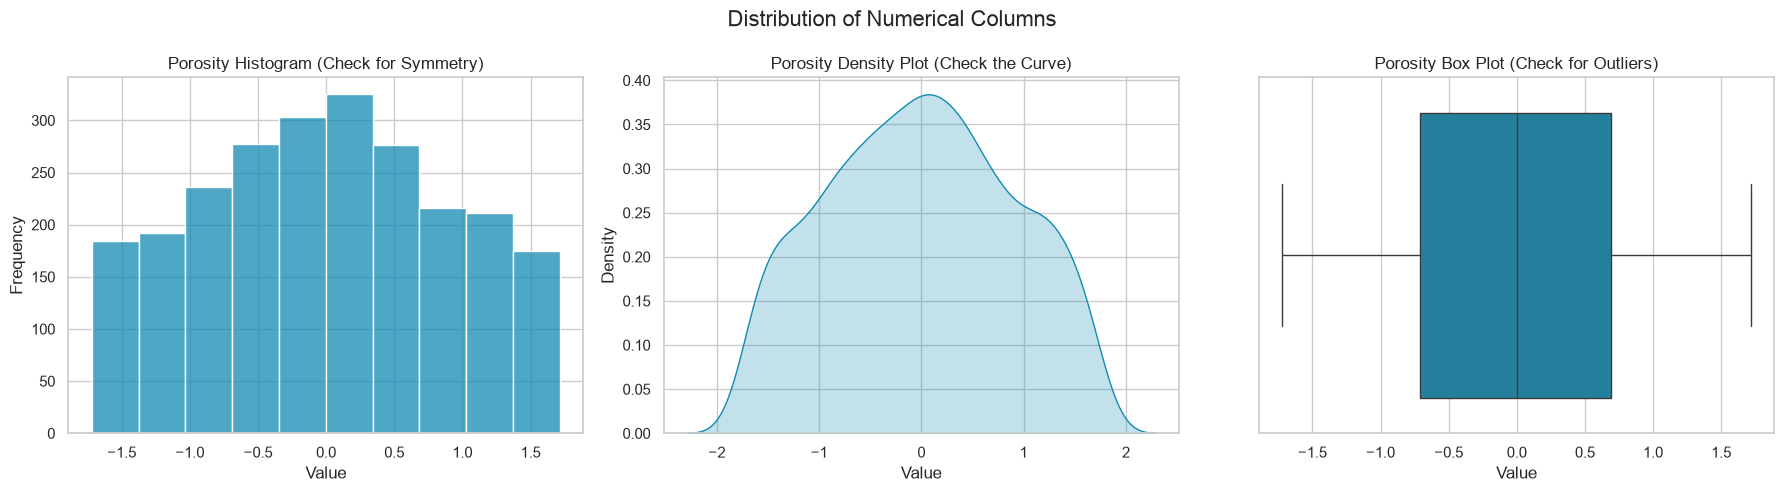

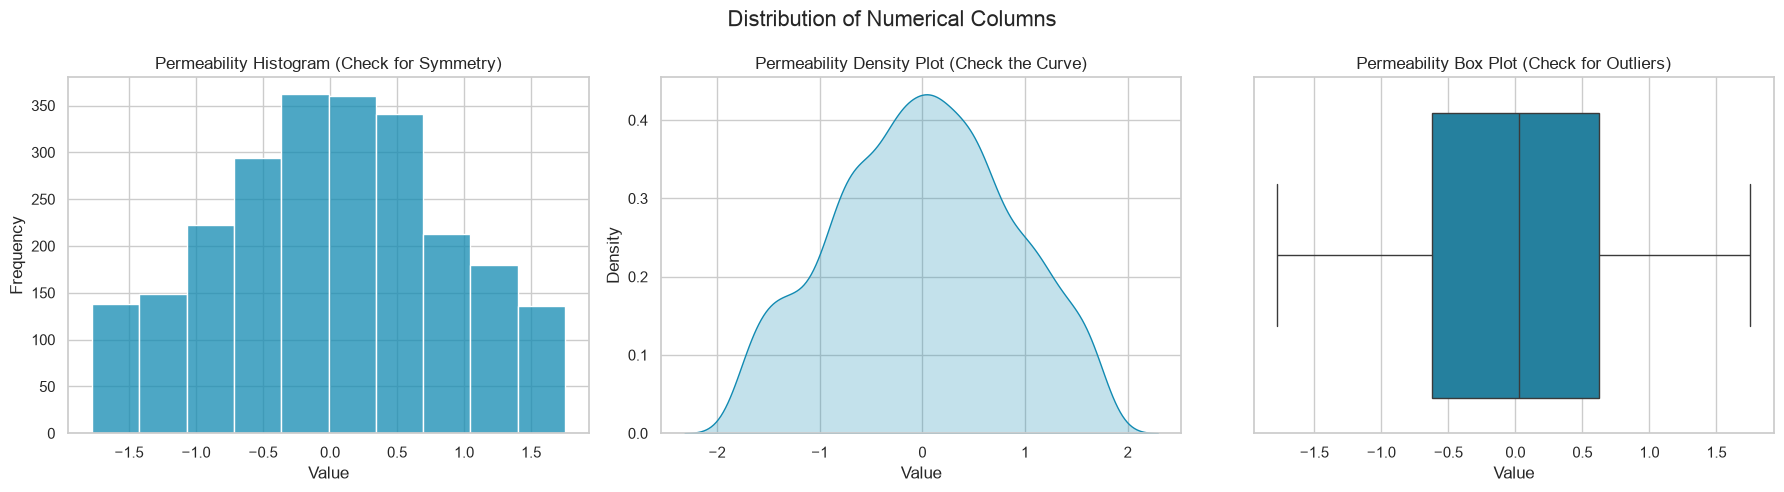

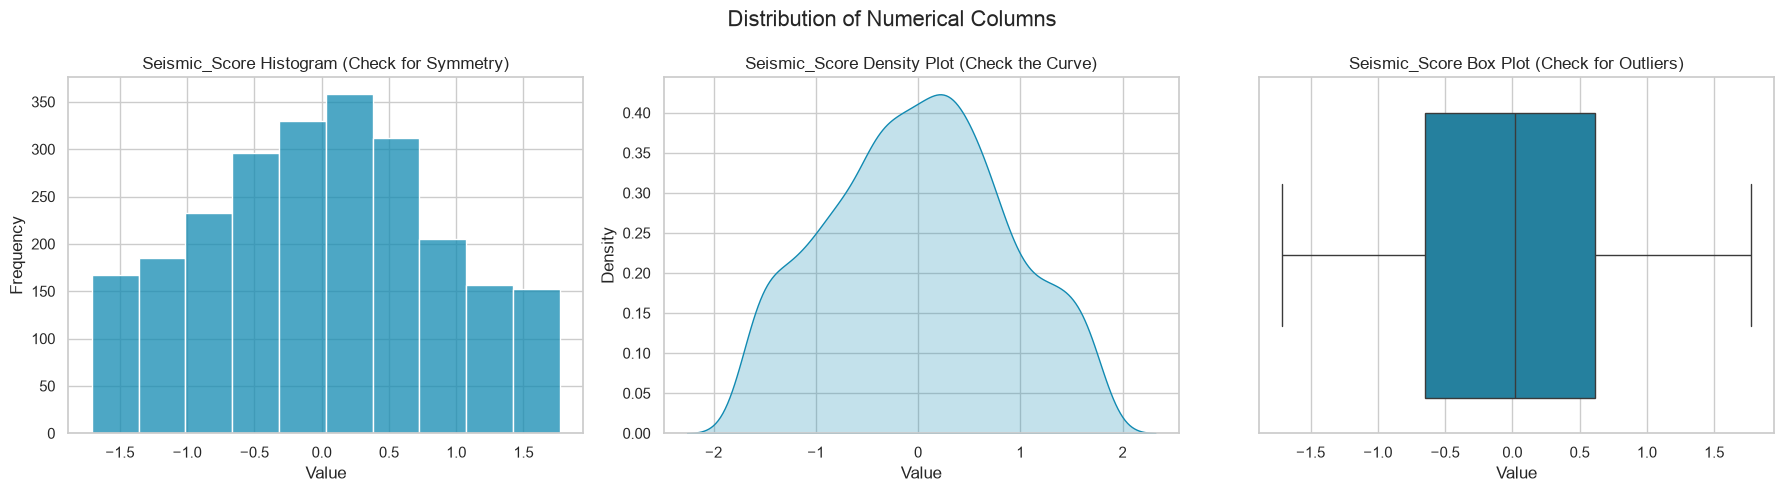

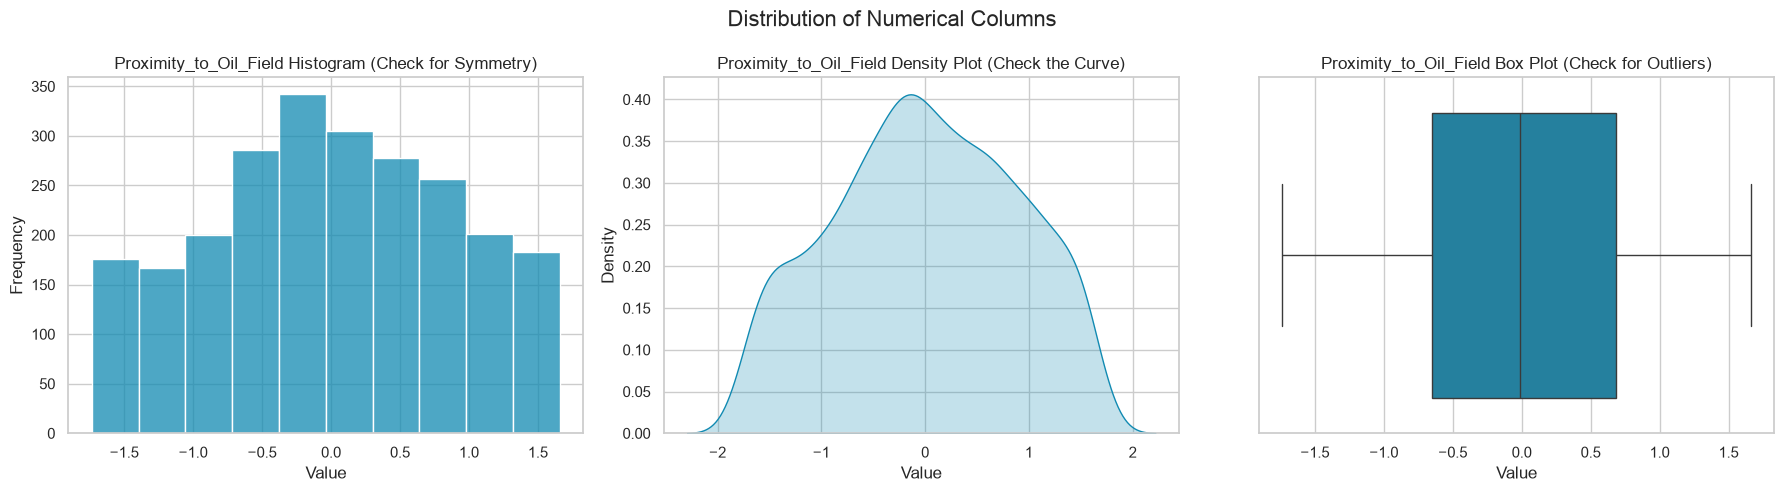

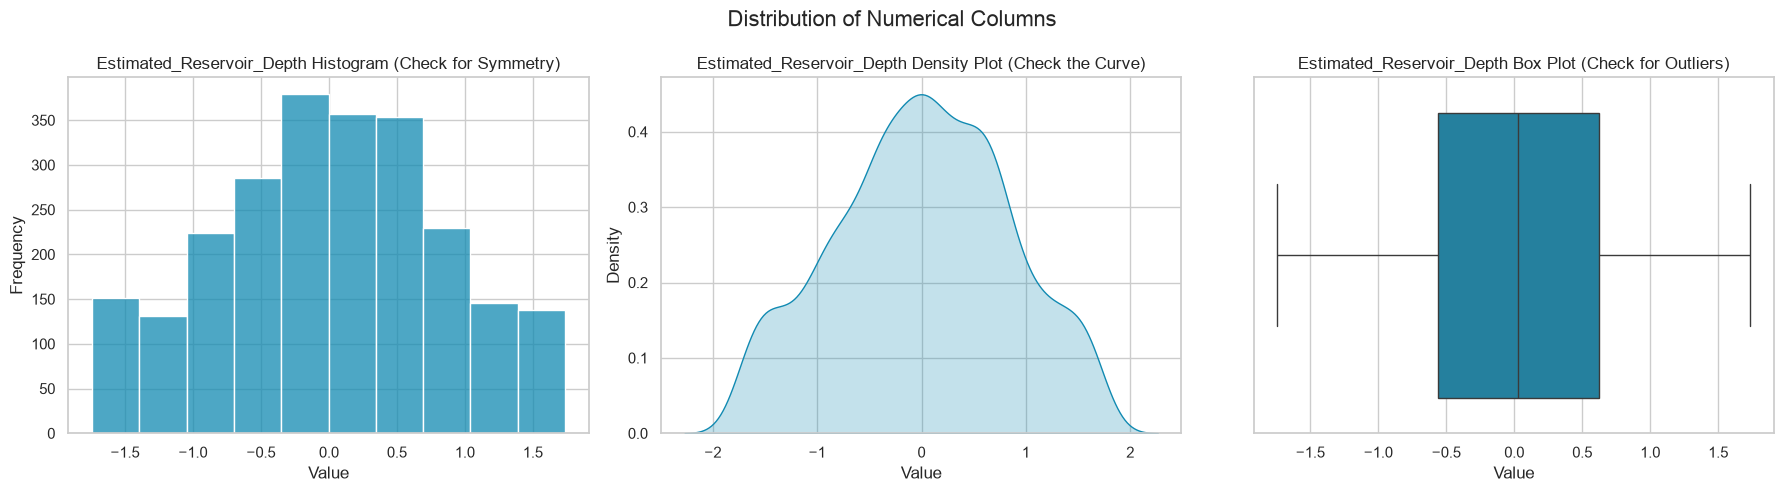

In [13]:
# plots to check for outliers after inputation of MICE
sns.set_theme(style="whitegrid")
primary_color = "#118ab2"

for i in numeric_features:
    # create a figure with 3 subplots (1 row, 3 columns)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Distribution of Numerical Columns', fontsize=16)

    # histogram
    sns.histplot(X_train_imputed[i], bins=10, color=primary_color, ax=axes[0])
    axes[0].set_title(f'{i} Histogram (Check for Symmetry)')
    axes[0].set_xlabel('Value')
    axes[0].set_ylabel('Frequency')

    # density plot
    sns.kdeplot(X_train_imputed[i], color=primary_color, fill=True, ax=axes[1])
    axes[1].set_title(f'{i} Density Plot (Check the Curve)')
    axes[1].set_xlabel('Value')
    axes[1].set_ylabel('Density')

    # boxplot
    sns.boxplot(x=X_train_imputed[i], color=primary_color, ax=axes[2])
    axes[2].set_title(f'{i} Box Plot (Check for Outliers)')
    axes[2].set_xlabel('Value')

    # display the charts
    plt.tight_layout()
    plt.show() 

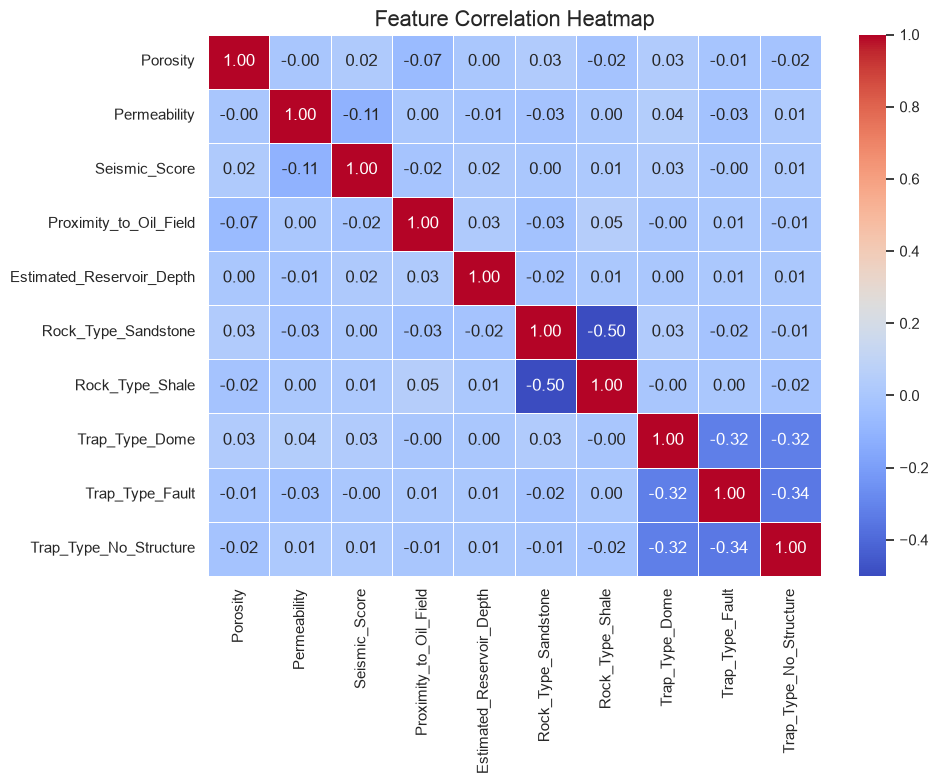

In [14]:
# feature Correlation Heatmap
plt.figure(figsize=(10, 8))
# select only numerical columns for correlation
corr_imputed_df = X_train_imputed.select_dtypes(include=[np.number])
sns.heatmap(corr_imputed_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()


## Phase 4: Standard Modeling (Baseline)
Train a baseline Random Forest model on the imputed data to establish initial performance metrics.


In [15]:
baseline_models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)
}

baseline_results = []

for name, model in baseline_models.items():
    model.fit(X_train_imputed, y_train)
    preds = model.predict(X_test_imputed)
    probs = model.predict_proba(X_test_imputed)[:, 1]
    
    baseline_results.append({
        'Model': name, 
        'Accuracy': accuracy_score(y_test, preds), 
        'Precision': precision_score(y_test, preds), 
        'Recall': recall_score(y_test, preds), 
        'F1 Score': f1_score(y_test, preds), 
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

baseline_df = pd.DataFrame(baseline_results).set_index('Model')
print("Baseline Models Performance")
print("-" * 40)
print(baseline_df.round(4))


Baseline Models Performance
----------------------------------------
               Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                        
Random Forest    0.8080     0.7321  0.4910    0.5878   0.7909
XGBoost          0.7880     0.6613  0.4910    0.5636   0.7770
LightGBM         0.7947     0.6864  0.4850    0.5684   0.7928
CatBoost         0.8114     0.7596  0.4731    0.5830   0.8142


### Brief Summary (Baseline Models)

Accuracy alone is not enough here because the target is imbalanced, so the other metrics tell us more about how the model behaves.

The precision tells us that this model would is quite good at detecting the presence of oil, the recall tells us that this model struggles to not miss the oil presence, the f1 score is quite weak when it comes to balancing whether or not the oil is been found when oil presence is raised or we miss a potential oil presence and the ROC-AUC is quite good at distinguishing between a rich oil area and barren wasteland. A major problem here is the model missing possible oil locations, which is worse than this model not causing many false alarms in this setting. So the next step/phase would focus on improving recall for class 1(Oil found). 




## Phase 5: Imbalance-Aware Model Tuning
Tune the models using RandomizedSearchCV with a focus on recall to better capture the minority class, and incorporate the imbalance ratio into the scale_pos_weight parameter for XGBoost and LightGBM.


In [ ]:
# calculate imbalance ratio
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# tune the models using RandomizedSearchCV with a focus on recall to better capture the minority class, 
# and incorporate the imbalance ratio into the scale_pos_weight parameter for XGBoost and LightGBM.

rfc_param_dist = {
    'n_estimators': randint(100, 301),
    'max_depth': randint(3, 8),
    'max_features': ['sqrt', 'log2', None],
    'class_weight': ['balanced']
}
rfc_search = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                                param_distributions=rfc_param_dist, n_iter=10, scoring='recall',
                                cv=cv_strategy, random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
rfc_search.fit(X_train_imputed, y_train)
best_rfc = rfc_search.best_estimator_

xgb_param_dist = {
    'n_estimators': randint(100, 301),
    'max_depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.15),
    'subsample': uniform(0.3, 0.7),
    'colsample_bytree': uniform(0.3, 0.7),
    'scale_pos_weight': [imbalance_ratio]
}
xgb_search = RandomizedSearchCV(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
                                param_distributions=xgb_param_dist, n_iter=10, scoring='recall', 
                                cv=cv_strategy, random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
xgb_search.fit(X_train_imputed, y_train)
best_xgb = xgb_search.best_estimator_

lgbm_param_dist = {
    'n_estimators': randint(100, 301),
    'max_depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.15),
    'subsample': uniform(0.3, 0.7),
    'colsample_bytree': uniform(0.3, 0.7),
    'scale_pos_weight': [imbalance_ratio]
}
lgbm_search = RandomizedSearchCV(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
                                 param_distributions=lgbm_param_dist, n_iter=10, scoring='recall', 
                                 cv=cv_strategy, random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
lgbm_search.fit(X_train_imputed, y_train)
best_lgbm = lgbm_search.best_estimator_

cat_param_dist = {
    'iterations': randint(100, 301),
    'depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.15),
    'auto_class_weights': ['Balanced']
}
cat_search = RandomizedSearchCV(CatBoostClassifier(random_state=RANDOM_STATE, verbose=0),
                                param_distributions=cat_param_dist, n_iter=10, scoring='recall', 
                                cv=cv_strategy, random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
cat_search.fit(X_train_imputed, y_train)
best_cat = cat_search.best_estimator_



# evaluate the tuned models
tuned_models = {'Tuned Random Forest': best_rfc,'Tuned XGBoost': best_xgb, 'Tuned LightGBM': best_lgbm, 'Tuned CatBoost': best_cat}
tuned_results = []

for name, model in tuned_models.items():
    preds = model.predict(X_test_imputed)
    probs = model.predict_proba(X_test_imputed)[:, 1]
    tuned_results.append({
        'Model': name, 
        'Accuracy': accuracy_score(y_test, preds), 
        'Precision': precision_score(y_test, preds), 
        'Recall': recall_score(y_test, preds), 
        'F1 Score': f1_score(y_test, preds), 
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

tuned_df = pd.DataFrame(tuned_results).set_index('Model')
print("Tuned Models Performance")
print("-" * 40)
print(tuned_df.round(4))


Tuned Models Performance
----------------------------------------
                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                              
Tuned Random Forest    0.7997     0.6358  0.6587    0.6471   0.8100
Tuned XGBoost          0.7613     0.5556  0.7186    0.6266   0.8158
Tuned LightGBM         0.7730     0.5779  0.6886    0.6284   0.8120
Tuned CatBoost         0.7796     0.5854  0.7186    0.6452   0.8160


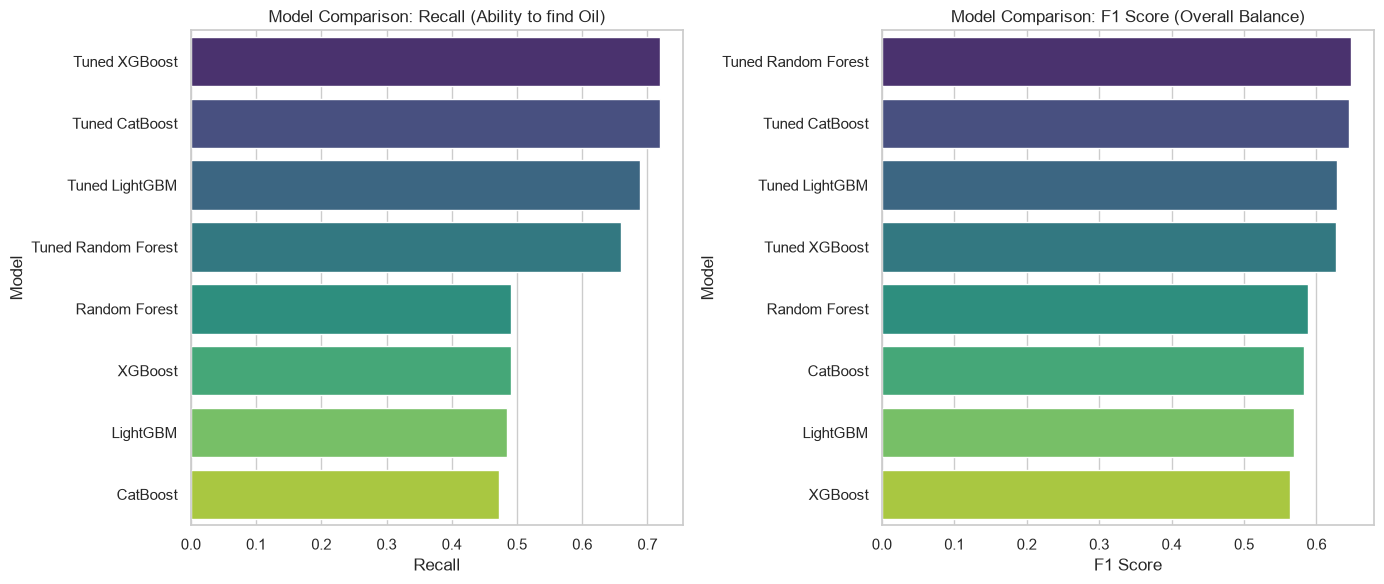

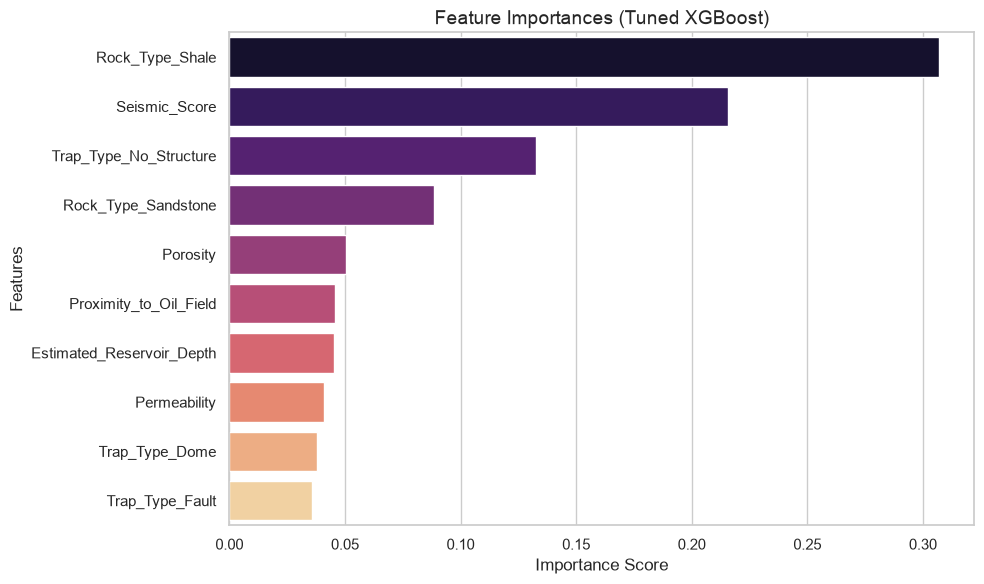

In [ ]:
# combine baseline and tuned results for plotting
all_results_df = pd.concat([baseline_df, tuned_df]).reset_index()

# plot Recall and F1 Score comparison 
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.barplot(data=all_results_df.sort_values(by='Recall', ascending=False), x='Recall', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('Model Comparison: Recall (Ability to find Oil)')

plt.subplot(1, 2, 2)
sns.barplot(data=all_results_df.sort_values(by='F1 Score', ascending=False), x='F1 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('Model Comparison: F1 Score (Overall Balance)')

plt.tight_layout()
plt.show()

# plot Feature Importances for the Model with the Best Recall
best_model_name = tuned_df['Recall'].idxmax()
best_model = tuned_models[best_model_name]

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    feat_imp = pd.Series(importances, index=X_train_imputed.columns).sort_values(ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x=feat_imp, y=feat_imp.index, hue=feat_imp.index, palette='magma', legend=False)
    plt.title(f'Feature Importances ({best_model_name})', fontsize=14)
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()


## Phase 6: Part 2 - Physics-Informed Preprocessing (Advanced Domain Logic)
To fulfill the requirements of Part 2, we implement a highly sophisticated, 5-stage physics-informed anomaly correction pipeline using a defensive programming architecture (Boolean flagging). This ensures the ML model adheres to the laws of physics (Athy's Law, Kozeny-Carman) and geological trapping mechanisms.


In [18]:
def apply_physics_rules(X_in, y_in=None):
    """
    Applies 5 hierarchical, physics-informed geological rules to clean the dataset.
    Uses boolean masks to prevent rules from spoiling each other.
    If y_in is provided (training set), it leverages Oil_Presence for Rule 2.
    """
    
    # X_in is the input DataFrame of features, y_in is the target series (optional)
    df = X_in.copy()
    
    if y_in is not None:
        df['Oil_Presence'] = y_in
        
    # initilize correction flags to track which rows have been modified by each rule
    df['flag_trap_corrected'] = False
    df['flag_rock_corrected'] = False
    df['flag_poro_corrected'] = False
    df['flag_perm_corrected'] = False
    

    # Rule 1: Structural Identification (Trap vs. Seismic Score)
    mask_r1 = (df['Trap_Type'] == 'No_Structure') & (df['Seismic_Score'] >= 0.8)
    df.loc[mask_r1, 'Trap_Type'] = 'Anticline'
    df.loc[mask_r1, 'flag_trap_corrected'] = True
    
    # Rule 2: Hydrocarbon Accumulation (Trap vs. Oil Presence)
    if 'Oil_Presence' in df.columns:
        mask_r2 = (df['Oil_Presence'] == 1) & (df['Trap_Type'] == 'No_Structure') & (~df['flag_trap_corrected'])
        df.loc[mask_r2, 'Trap_Type'] = 'Stratigraphic'
        df.loc[mask_r2, 'flag_trap_corrected'] = True
        num_r2 = mask_r2.sum()
    else:
        num_r2 = 0 # Cannot apply Rule 2 to inference/test sets
        
    # Rule 3: Lithology Fluid Flow Constraints (Shale Anomalies)
    # 3A: Reclassify the obvious reservoir rock mislabeled as Shale
    mask_r3_reclassify = (df['Rock_Type'] == 'Shale') & (df['Porosity'] > 15.0) & (df['Permeability'] > 50.0)
    df.loc[mask_r3_reclassify, 'Rock_Type'] = 'Sandstone'
    df.loc[mask_r3_reclassify, 'flag_rock_corrected'] = True
    
    # 3B: Cap mathematically impossible permeability in true Shales
    mask_r3_cap = (df['Rock_Type'] == 'Shale') & (df['Permeability'] > 10.0) & (~df['flag_rock_corrected'])
    df.loc[mask_r3_cap, 'Permeability'] = 0.001
    df.loc[mask_r3_cap, 'flag_perm_corrected'] = True
    
    # Rule 4: Rock Compaction (Depth vs. Porosity via Athy's Law)
    mask_r4 = (df['Estimated_Reservoir_Depth'] > 4000) & (df['Porosity'] > 25.0) & (~df['flag_poro_corrected'])
    # Apply exponential decay approximation (phi = phi_0 * e^(-c*z))
    df.loc[mask_r4, 'Porosity'] = 40.0 * np.exp(-0.0003 * df.loc[mask_r4, 'Estimated_Reservoir_Depth'])
    df.loc[mask_r4, 'flag_poro_corrected'] = True
    
    # Rule 5: Kozeny-Carman Relationship (Porosity vs. Permeability)
    mask_r5 = (df['Rock_Type'] == 'Sandstone') & (df['Porosity'] > 20.0) & (df['Permeability'] < 10.0) & (~df['flag_perm_corrected'])
    # k scales roughly proportionally with (phi^3) / ((100-phi)^2) * Constant
    df.loc[mask_r5, 'Permeability'] = (df.loc[mask_r5, 'Porosity']**3) / ((100.0 - df.loc[mask_r5, 'Porosity'])**2) * 50.0
    df.loc[mask_r5, 'flag_perm_corrected'] = True
    
    print("--- Physics-Informed Corrections Applied ---")
    print(f"Rule 1 (Structural ID) Traps Fixed: {mask_r1.sum()}")
    print(f"Rule 2 (Hydrocarbon Accumulation) Traps Fixed: {num_r2}")
    print(f"Rule 3 (Shale -> Sandstone Reclassification): {mask_r3_reclassify.sum()}")
    print(f"Rule 3 (Shale Permeability Cap): {mask_r3_cap.sum()}")
    print(f"Rule 4 (Athy's Law Compaction Fix): {mask_r4.sum()}")
    print(f"Rule 5 (Kozeny-Carman Permeability Fix): {mask_r5.sum()}\n")
    
    # cleanup the flags and target
    flags = ['flag_trap_corrected', 'flag_rock_corrected', 'flag_poro_corrected', 'flag_perm_corrected']
    df.drop(columns=flags, inplace=True)
    if 'Oil_Presence' in df.columns:
        df.drop(columns=['Oil_Presence'], inplace=True)
        
    return df

# # apply the rules to the training and testing or validation sets
# print("Processing Training Set:")
# X_train_physics = apply_physics_rules(X_train, y_train)

# print("Processing Validation Set:")
# X_test_physics = apply_physics_rules(X_test) # No y_test is passed to prevent target leakage


In [19]:

def add_advanced_petroleum_features(X_in):
    """
    Calculates advanced geological and petrophysical indicators.
    """
    df = X_in.copy()
    
    # convert Porosity to a fraction for formulas (preventing division by zero)
    phi_frac = (df['Porosity'] / 100.0) + 1e-6
    
    # 1. Reservoir Quality Index (RQI)
    # Standard formula: RQI = 0.0314 * sqrt(Permeability / Porosity)
    df['Reservoir_Quality_Index'] = 0.0314 * np.sqrt(df['Permeability'] / phi_frac)
    
    # 2. Flow Capacity (Proxy)
    # Usually Permeability * Thickness (kh). Lacking thickness, we proxy the 
    # transmissibility potential by interacting Permeability with Porosity fraction.
    df['Flow_Capacity_Proxy'] = df['Permeability'] * phi_frac
    
    # 3. Storage Capacity (Proxy)
    # Usually Porosity * Thickness (Phi-h). We use a logarithmic scale of depth 
    # as a structural proxy, assuming deeper targets have higher gross rock volumes.
    df['Storage_Capacity_Proxy'] = df['Porosity'] * np.log1p(df['Estimated_Reservoir_Depth'])
    
    # 4. Migration Potential
    # Hydrocarbons migrate from source to trap. Shorter distance = higher potential.
    df['Migration_Potential'] = 1.0 / (df['Proximity_to_Oil_Field'] + 1e-6)
    
    # 5. Trap Effectiveness
    # A high seismic score is only useful if a physical trap exists to catch the oil.
    trap_exists = (df['Trap_Type'] != 'No_Structure').astype(int)
    df['Trap_Effectiveness'] = df['Seismic_Score'] * trap_exists
    
    # 6. Distance-Seismic Interaction
    # "Hotspot" indicator: High seismic confidence combined with close proximity.
    df['Distance_Seismic_Interaction'] = df['Seismic_Score'] / (df['Proximity_to_Oil_Field'] + 1e-6)
    
    # 7. Reservoir Confidence (Meta-Feature)
    # An ensemble index multiplying the three strongest geological viability pillars.
    df['Reservoir_Confidence'] = df['Reservoir_Quality_Index'] * df['Seismic_Score'] * df['Migration_Potential']
    
    return df

In [20]:
# 1. Apply Rule-Based Corrections
X_train_physics = apply_physics_rules(X_train, y_train)
X_test_physics = apply_physics_rules(X_test)

# 2. Add Advanced Petroleum Features
X_train_engineered = add_advanced_petroleum_features(X_train_physics)
X_test_engineered = add_advanced_petroleum_features(X_test_physics)

# 3. Dynamically capture ALL columns (original + new) for the preprocessor
numerical_cols = X_train_engineered.select_dtypes(include=['float64', 'int64']).columns.tolist()

# # 4. Push through your Pipeline (MICE Imputer + StandardScaler + OneHotEncoder)
# X_train_final = preprocessor.fit_transform(X_train_engineered)
# X_test_final = preprocessor.transform(X_test_engineered)
print('Numerical Columns:', numerical_cols)

--- Physics-Informed Corrections Applied ---
Rule 1 (Structural ID) Traps Fixed: 79
Rule 2 (Hydrocarbon Accumulation) Traps Fixed: 82
Rule 3 (Shale -> Sandstone Reclassification): 170
Rule 3 (Shale Permeability Cap): 296
Rule 4 (Athy's Law Compaction Fix): 47
Rule 5 (Kozeny-Carman Permeability Fix): 1

--- Physics-Informed Corrections Applied ---
Rule 1 (Structural ID) Traps Fixed: 17
Rule 2 (Hydrocarbon Accumulation) Traps Fixed: 0
Rule 3 (Shale -> Sandstone Reclassification): 47
Rule 3 (Shale Permeability Cap): 60
Rule 4 (Athy's Law Compaction Fix): 11
Rule 5 (Kozeny-Carman Permeability Fix): 0

Numerical Columns: ['Porosity', 'Permeability', 'Seismic_Score', 'Proximity_to_Oil_Field', 'Estimated_Reservoir_Depth', 'Reservoir_Quality_Index', 'Flow_Capacity_Proxy', 'Storage_Capacity_Proxy', 'Migration_Potential', 'Trap_Effectiveness', 'Distance_Seismic_Interaction', 'Reservoir_Confidence']


In [21]:
X_train_engineered.head()

,Rock_Type,Porosity,Permeability,Trap_Type,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Reservoir_Quality_Index,Flow_Capacity_Proxy,Storage_Capacity_Proxy,Migration_Potential,Trap_Effectiveness,Distance_Seismic_Interaction,Reservoir_Confidence
1449,Limestone,NaN,NaN,Dome,NaN,NaN,3620.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
943,Sandstone,22.398096,104.155551,Anticline,0.953322,NaN,4778.0,0.677118,23.328965,189.756370,NaN,0.953322,NaN,NaN
826,Limestone,15.266558,NaN,Anticline,NaN,1.812146,2025.0,NaN,NaN,116.236802,0.551832,NaN,NaN,NaN
2237,Sandstone,2.847253,137.598667,Dome,0.305531,1.653791,NaN,2.182811,3.917920,NaN,0.604671,0.305531,0.184746,0.403265
881,Sandstone,8.977453,845.491885,Dome,0.246705,0.864724,4587.0,3.047231,75.904479,75.690693,1.156437,0.246705,0.285299,0.869373


In [22]:
# analyze missing values across all engineered columns
print("Missing Values Analysis")
print("-"*40)

physics_missing_data = pd.DataFrame({
    'Column': X_train_engineered.columns,
    'Missing_Count': X_train_engineered.isnull().sum(),
    'Missing_Percentage': (X_train_engineered.isnull().sum() / len(X_train_engineered) * 100).round(2)
})
physics_missing_data = physics_missing_data[physics_missing_data['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

print("\n")
print(physics_missing_data.to_string(index=False))
print("\n")

Missing Values Analysis
----------------------------------------


                      Column  Missing_Count  Missing_Percentage
        Reservoir_Confidence           1907               79.62
      Storage_Capacity_Proxy           1387               57.91
     Reservoir_Quality_Index           1326               55.37
         Flow_Capacity_Proxy           1326               55.37
Distance_Seismic_Interaction           1302               54.36
   Estimated_Reservoir_Depth           1003               41.88
                Permeability            949               39.62
               Seismic_Score            825               34.45
          Trap_Effectiveness            825               34.45
      Proximity_to_Oil_Field            750               31.32
         Migration_Potential            750               31.32
                    Porosity            654               27.31




In [23]:
# dropping columns with missing values greater than 50%
threshold = 50.0
cols_to_drop = physics_missing_data[physics_missing_data['Missing_Percentage'] > threshold]['Column'].tolist()
X_train_engineered.drop(columns=cols_to_drop, inplace=True)
X_test_engineered.drop(columns=cols_to_drop, inplace=True)

numerical_cols = X_train_engineered.select_dtypes(include=['float64', 'int64']).columns.tolist()
print(numerical_cols)

['Porosity', 'Permeability', 'Seismic_Score', 'Proximity_to_Oil_Field', 'Estimated_Reservoir_Depth', 'Migration_Potential', 'Trap_Effectiveness']


## Phase 7: Part 2 Modeling (Physics-Informed Model Training)
Now that the data is physically sound, we pass the `X_train_engineered` variable through the exact same MICE Imputation + Scaling pipeline to ensure a fair comparison with Part 1. We then retrain our best models.


In [24]:
physics_preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numerical_cols),
        ('cat', cat_pipeline, categorical_cols)
    ],
    remainder='passthrough'
)


X_train_phys_imputed_processed = physics_preprocessor.fit_transform(X_train_engineered)
X_test_phys_imputed_processed = physics_preprocessor.transform(X_test_engineered)

# extract new feature names because our domain rules created new Trap categories,
# that is the OneHotEncoder generated 11 columns
physics_feature_names = (
    numerical_cols + 
    physics_preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_cols).tolist()
)

X_train_phys_imputed = pd.DataFrame(X_train_phys_imputed_processed, columns=physics_feature_names, index=X_train.index)
X_test_phys_imputed = pd.DataFrame(X_test_phys_imputed_processed, columns=physics_feature_names, index=X_test.index)

print("Physics-Informed Preprocessing complete. No data leakage occurred.")
print('Remaining missing values in physics-informed train set:', X_train_phys_imputed.isna().sum().sum())
print('Remaining missing values in physics-informed test set:', X_test_phys_imputed.isna().sum().sum())

print('Physics Feature Names:', physics_feature_names)


Physics-Informed Preprocessing complete. No data leakage occurred.
Remaining missing values in physics-informed train set: 0
Remaining missing values in physics-informed test set: 0
Physics Feature Names: ['Porosity', 'Permeability', 'Seismic_Score', 'Proximity_to_Oil_Field', 'Estimated_Reservoir_Depth', 'Migration_Potential', 'Trap_Effectiveness', 'Rock_Type_Sandstone', 'Rock_Type_Shale', 'Trap_Type_Dome', 'Trap_Type_Fault', 'Trap_Type_No_Structure', 'Trap_Type_Stratigraphic']


/Users/USER/Desktop/datathon/spe_dseat_datathon/ml_venv/lib/python3.14/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [25]:
# # plots to check for outliers after inputation of MICE in the physics-informed dataset
# sns.set_theme(style="whitegrid")
# primary_color = "#118ab2"

# for i in numeric_features:
#     # create a figure with 3 subplots (1 row, 3 columns)
#     fig, axes = plt.subplots(1, 3, figsize=(18, 5))
#     fig.suptitle('Distribution of Numerical Columns', fontsize=16)

#     # histogram
#     sns.histplot(X_train_phys_imputed[i], bins=10, color=primary_color, ax=axes[0])
#     axes[0].set_title(f'{i} Histogram (Check for Symmetry)')
#     axes[0].set_xlabel('Value')
#     axes[0].set_ylabel('Frequency')

#     # density plot
#     sns.kdeplot(X_train_phys_imputed[i], color=primary_color, fill=True, ax=axes[1])
#     axes[1].set_title(f'{i} Density Plot (Check the Curve)')
#     axes[1].set_xlabel('Value')
#     axes[1].set_ylabel('Density')

#     # boxplot
#     sns.boxplot(x=X_train_phys_imputed[i], color=primary_color, ax=axes[2])
#     axes[2].set_title(f'{i} Box Plot (Check for Outliers)')
#     axes[2].set_xlabel('Value')

#     # display the charts
#     plt.tight_layout()
#     plt.show() 

In [26]:
# retrain the best models from Part 1 on the Part 2 Physics Data
p2_best_xgb = XGBClassifier(**best_xgb.get_params())
p2_best_xgb.fit(X_train_phys_imputed, y_train)

p2_best_cat = CatBoostClassifier(**best_cat.get_params())
p2_best_cat.fit(X_train_phys_imputed, y_train)

# Evaluate Physics-Informed Models
phys_results = []
for name, model in {'Physics XGBoost': p2_best_xgb, 'Physics CatBoost': p2_best_cat}.items():
    preds = model.predict(X_test_phys_imputed)
    probs = model.predict_proba(X_test_phys_imputed)[:, 1]
    phys_results.append({
        'Model': name, 
        'Accuracy': accuracy_score(y_test, preds), 
        'Precision': precision_score(y_test, preds), 
        'Recall': recall_score(y_test, preds), 
        'F1 Score': f1_score(y_test, preds), 
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

phys_df = pd.DataFrame(phys_results).set_index('Model')
print("\n--- Physics-Informed Models Performance ---")
print(phys_df.round(4))


--- Physics-Informed Models Performance ---
                  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                           
Physics XGBoost     0.7563     0.5488  0.7066    0.6178   0.7936
Physics CatBoost    0.7529     0.5459  0.6766    0.6043   0.7827


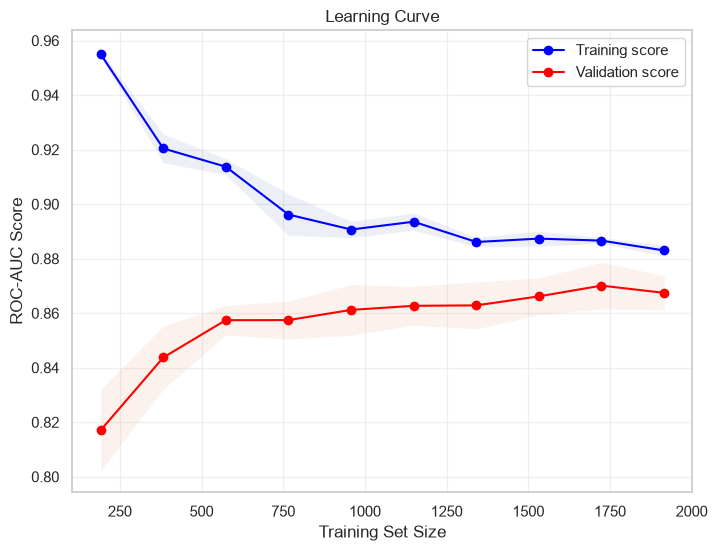

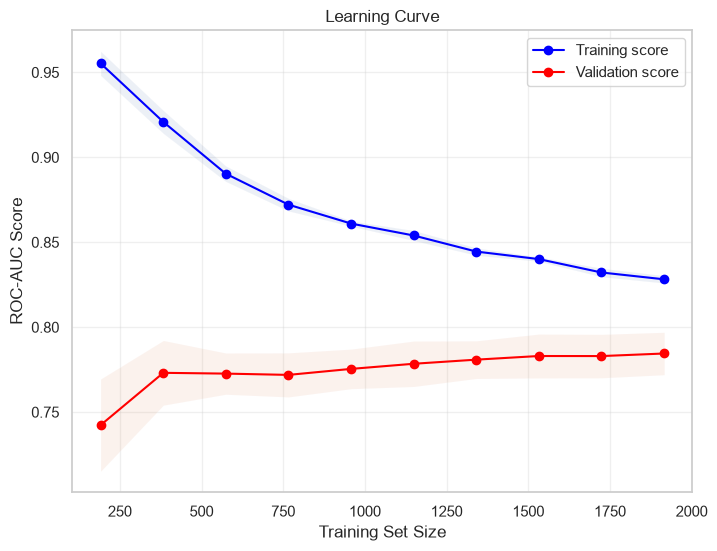

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, X, y, cv=5, train_sizes=np.linspace(0.1, 1.0, 10)):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, cv=cv, train_sizes=train_sizes, 
        scoring='roc_auc',
        n_jobs=-1
    )
    
    # Calculate mean scores
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    
    plt.figure(figsize=(8, 6))
    plt.plot(train_sizes, train_mean, 'o-', color="blue", label="Training score")
    plt.plot(train_sizes, val_mean, 'o-', color="red", label="Validation score")

    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha = 0.1)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha = 0.1)
    
    plt.title('Learning Curve')
    plt.xlabel('Training Set Size')
    plt.ylabel('ROC-AUC Score')
    plt.legend(loc="best")
    plt.grid(alpha = 0.3)
    plt.show()

plot_learning_curve(p2_best_xgb, X_train_phys_imputed, y_train)
plot_learning_curve(best_xgb, X_train_imputed, y_train)


### Visualizing the Impact of Physics-Informed Rules
To validate that our domain logic worked, we compare the raw dataset to the physics-informed dataset across three critical geological relationships:

1. **Depth vs. Porosity (Validating Rule 4 - Rock Compaction):** We use a scatter plot to identify deep-earth outliers. *What to look for:* In the "Raw" plot, you will see impossible points in the top-right (deep depth, high porosity). In the "Physics-Informed" plot, you will see those points physically crushed down onto an exponential decay curve matching Athy's Law.
2. **Porosity vs. Permeability (Validating Rules 3 & 5 - Fluid Flow):** We use a scatter plot with a logarithmic Y-axis (since permeability spans orders of magnitude) colored by Rock Type. *What to look for:* In the "Raw" plot, you will see Sandstone with zero permeability despite high porosity, and Shale with massive permeability. In the "Physics-Informed" plot, Sandstone will form a positive upward trend (Kozeny-Carman), and Shale will be forcefully flatlined at the bottom.


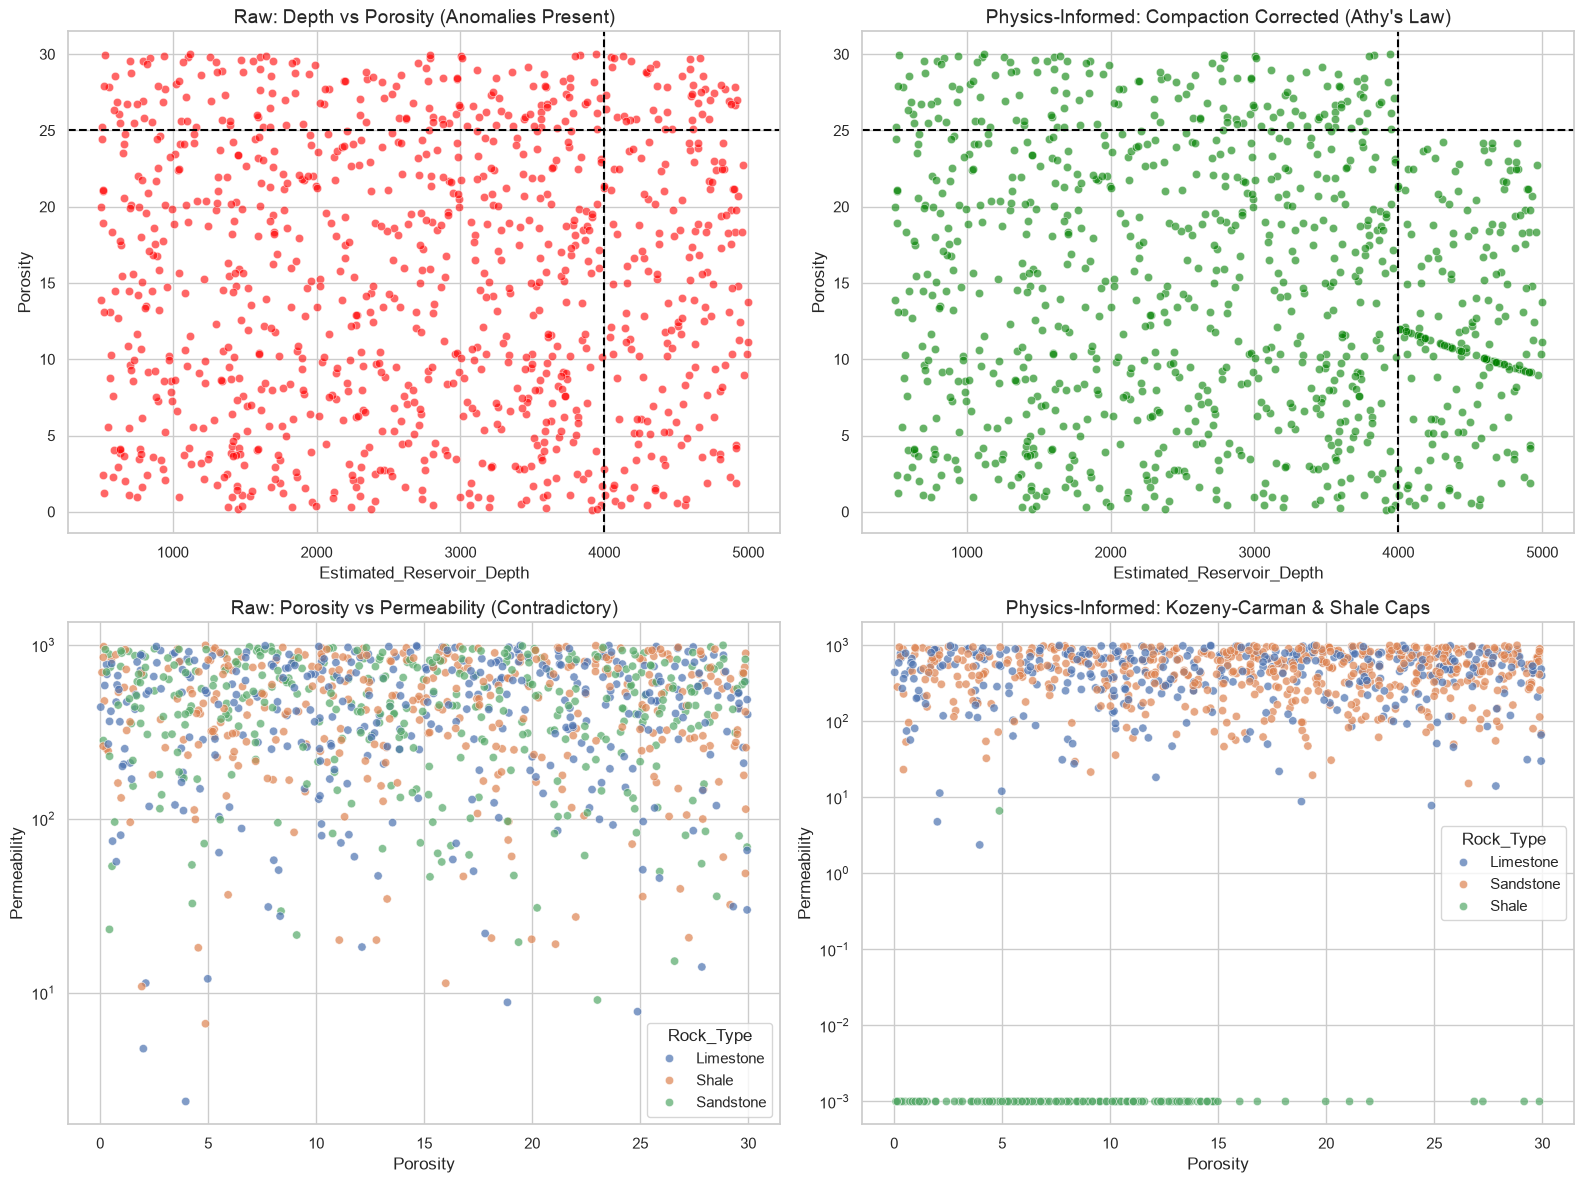

In [28]:
df_raw = X_train.copy()
df_raw['Oil_Presence'] = y_train
df_phys = X_train_engineered.copy()
df_phys['Oil_Presence'] = y_train

# Scatter Comparisons (Depth/Porosity and Porosity/Perm)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1A: Raw Depth vs Porosity
sns.scatterplot(data=df_raw, x='Estimated_Reservoir_Depth', y='Porosity', ax=axes[0, 0], alpha=0.6, color='red')
axes[0, 0].set_title('Raw: Depth vs Porosity (Anomalies Present)', fontsize=14)
axes[0, 0].axvline(x=4000, color='black', linestyle='--')
axes[0, 0].axhline(y=25, color='black', linestyle='--')

# 1B: Corrected Depth vs Porosity
sns.scatterplot(data=df_phys, x='Estimated_Reservoir_Depth', y='Porosity', ax=axes[0, 1], alpha=0.6, color='green')
axes[0, 1].set_title("Physics-Informed: Compaction Corrected (Athy's Law)", fontsize=14)
axes[0, 1].axvline(x=4000, color='black', linestyle='--')
axes[0, 1].axhline(y=25, color='black', linestyle='--')

# 2A: Raw Porosity vs Permeability (Log Scale)
sns.scatterplot(data=df_raw, x='Porosity', y='Permeability', hue='Rock_Type', ax=axes[1, 0], alpha=0.7)
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Raw: Porosity vs Permeability (Contradictory)', fontsize=14)

# 2B: Corrected Porosity vs Permeability (Log Scale)
sns.scatterplot(data=df_phys, x='Porosity', y='Permeability', hue='Rock_Type', ax=axes[1, 1], alpha=0.7)
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Physics-Informed: Kozeny-Carman & Shale Caps', fontsize=14)

plt.tight_layout()
plt.show()


## Phase 8: Final Evaluation & Submission Generation
Load the hidden test set, process it through both pipelines (Standard and Physics-Informed), and generate the final CSV files for the competition.
